<a href="https://colab.research.google.com/github/luiseduaardo/credit-card-fraud-detection/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 💳 | Aplicação de Ensembles em detecção de fraudes em cartões de crédito

In [51]:
# Execute caso esteja usando Google Colab
system("git clone https://github.com/luiseduaardo/credit-card-fraud-detection")
setwd("credit-card-fraud-detection")

## Introdução

### Sobre o problema

Fraudes em cartões de crédito são uma classe de problemas no Setor Financeiro Nacional (SFN) que apresenta uma grande relevância dado o prejuízo às instituições financeiras e aos clientes, e detectá-las automaticamente é um problema clássico de classificação binária, onde cada transação pode ser classificada como legítima ou fraudulenta.

Existe uma dificuldade central nesse problema. As fraudes são raras, o que causa um forte desbalanceamento das classes. Um classificador treinado nessas condições tende a favorecer a classe majoritária e pode alcançar acurácia alta sem identificar quase nenhuma fraude, justamente o caso que mais importa.

Além disso, modelos isolados enfrentam outras limitações nesse cenário. Eles podem ser sensíveis a ruído, ter dificuldade de captar relações não lineares entre os atributos e deixar de detectar fraudes cujo comportamento se parece com o de transações normais.

### Sobre os ensembles

No Projeto 1, realizamos um estudo conceitual e estatístico a respeito dos métodos de *ensemble*, que consistem na combinação de vários modelos para obter um preditor mais completo do que qualquer um deles sozinho. Vimos que esses modelos podem ser classificados de diversas formas, dentre elas:

| Método | Tipo de ensemble | Como ocorre o treinamento? | Como combina as previsões? | Objetivo principal | Exemplos |
|---|---|---|---|---|---|
| **Bagging** | Homogêneo | Em paralelo, cada um sobre uma amostra *bootstrap* (sorteada com reposição) | Votação majoritária (classificação) ou média (regressão) | Reduzir a variância (*overfitting*) | Random Forest |
| **Boosting** | Homogêneo | Em sequência, cada novo modelo focado nos erros dos anteriores | Soma ponderada dos modelos, controlada pela taxa de aprendizado | Reduzir o viés (*underfitting*) | AdaBoost, XGBoost |
| **Stacking** | Heterogêneo | Em paralelo, modelos de tipos diferentes treinados com validação cruzada (k-fold) | Um meta-modelo usa as previsões dos modelos-base como atributos e toma a decisão final | Reduzir viés e variância, aproveitando os erros diferentes de cada modelo | Vários métodos de classificação |

O sucesso desses métodos em problemas que já foram aplicados na realidade motiva a aplicação nesse nosso problema. A nossa hipótese inicial levantada é que combinar modelos permite contornar as limitações de classificadores individuais em dados desbalanceados e melhorar a detecção da classe minoritária.


### Objetivos

Com essa análise, buscamos responder o seguinte:

Em um conjunto de transações de cartão de crédito com classes desbalanceadas, os métodos de ensemble (Bagging, Boosting e Stacking) detectam fraudes melhor do que modelos de classificação individuais? Qual desses métodos apresenta o melhor desempenho?

Para isso, pretendemos:

1. Explorar os dados para identificar quais características diferenciam transações fraudulentas das legítimas;
2. Validar estatisticamente, com testes de hipóteses, os padrões encontrados na análise exploratória;
3. Treinar modelos individuais de referência (*baseline*) e modelos de ensemble (Random Forest, XGBoost e Stacking);
4. Comparar os modelos com métricas adequadas.

### Descrição dos Dados

O dataset utilizado é o [Credit Card Fraud Detection](https://www.kaggle.com/datasets/miadul/credit-card-fraud-detection-dataset), que extraímos da plataforma Kaggle.

Esse conjunto de dados contém 10.000 transações simuladas de cartões de crédito, legítimas e fraudulentas, com 9 colunas de variáveis e uma de  variável-alvo, que é `is_fraud`.

O dataset possui o seguinte dicionário de dados:

| Variável | Tipo de variável | Descrição |
|---|---|---|
| `transaction_id` | Identificador | Código único da transação |
| `amount` | Numérica contínua | Valor da transação |
| `transaction_hour` | Numérica discreta | Hora do dia em que a transação ocorreu |
| `merchant_category` | Categórica | Tipo de estabelecimento |
| `foreign_transaction` | Binária | Indica se a transação é internacional |
| `location_mismatch` | Binária | Indica divergência entre o local de faturamento do cartão e o local da transação |
| `device_trust_score` | Numérica contínua | Pontuação de confiança do dispositivo usado na transação |
| `velocity_last_24h` | Numérica discreta | Número de transações feitas com o cartão nas últimas 24 horas |
| `cardholder_age` | Numérica discreta | Idade do titular do cartão |
| `is_fraud` | Binária | Variável-alvo, que indica 1 = fraude, 0 = legítima |

## Análise Exploratória de Dados

Esta seção descreve o arquivo incluído no repositório (`data/credit_card_fraud_10k.csv`). As transações são simuladas; as conclusões descrevem este conjunto, sem pressupor representatividade do mercado real. Executar o notebook a partir da raiz do repositório com um kernel **R** (pacotes básicos de R bastam).

### 2.1 Carregamento, tipos e qualidade

`transaction_id` é identificador e não deve ser tratado como variável explicativa. Verificamos tipos, dimensões, ausências, duplicatas e valores fora do domínio antes de analisar associações. Se uma checagem falhar em outra versão do CSV, o código interrompe a análise para que a correção seja documentada, em vez de alterar dados silenciosamente.

In [52]:
caminho <- file.path("data", "credit_card_fraud_10k.csv")
dados <- read.csv(caminho, stringsAsFactors = FALSE)

In [53]:
colunas <- c("transaction_id", "amount", "transaction_hour", "merchant_category",
             "foreign_transaction", "location_mismatch", "device_trust_score",
             "velocity_last_24h", "cardholder_age", "is_fraud")
stopifnot(identical(names(dados), colunas))
cat("Dimensões:", nrow(dados), "linhas x", ncol(dados), "colunas\n")
str(dados)
head(dados)
summary(dados)
data.frame(variavel = names(dados), ausentes = colSums(is.na(dados)))
cat("Linhas duplicadas:", sum(duplicated(dados)), "| IDs duplicados:",
    sum(duplicated(dados$transaction_id)), "\n")
stopifnot(!anyNA(dados), !anyDuplicated(dados), !anyDuplicated(dados$transaction_id),
          all(dados$is_fraud %in% 0:1), all(dados$foreign_transaction %in% 0:1),
          all(dados$location_mismatch %in% 0:1),
          all(dados$transaction_hour %in% 0:23), all(dados$amount >= 0),
          all(dados$velocity_last_24h >= 0),
          all(dados$device_trust_score >= 0 & dados$device_trust_score <= 100),
          all(dados$cardholder_age >= 18))
dados$is_fraud <- factor(dados$is_fraud, levels = 0:1, labels = c("Legítima", "Fraude"))
dados$merchant_category <- factor(dados$merchant_category)
dados$foreign_transaction <- factor(dados$foreign_transaction, levels = 0:1,
                                     labels = c("Não", "Sim"))
dados$location_mismatch <- factor(dados$location_mismatch, levels = 0:1,
                                   labels = c("Não", "Sim"))


Dimensões: 10000 linhas x 10 colunas
'data.frame':	10000 obs. of  10 variables:
 $ transaction_id     : int  1 2 3 4 5 6 7 8 9 10 ...
 $ amount             : num  84.5 541.8 237 164.3 30.5 ...
 $ transaction_hour   : int  22 3 17 4 15 13 18 13 8 5 ...
 $ merchant_category  : chr  "Electronics" "Travel" "Grocery" "Grocery" ...
 $ foreign_transaction: int  0 1 0 0 0 0 0 0 0 0 ...
 $ location_mismatch  : int  0 0 0 1 0 0 0 0 0 0 ...
 $ device_trust_score : int  66 87 49 72 79 90 48 68 80 59 ...
 $ velocity_last_24h  : int  3 1 1 3 0 2 1 1 0 1 ...
 $ cardholder_age     : int  40 64 61 34 44 46 28 40 21 34 ...
 $ is_fraud           : int  0 0 0 0 0 0 0 0 0 0 ...


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
,<int>,<dbl>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>
1,1,84.47,22,Electronics,0,0,66,3,40,0
2,2,541.82,3,Travel,1,0,87,1,64,0
3,3,237.01,17,Grocery,0,0,49,1,61,0
4,4,164.33,4,Grocery,0,1,72,3,34,0
5,5,30.53,15,Food,0,0,79,0,44,0
6,6,30.53,13,Clothing,0,0,90,2,46,0


 transaction_id      amount        transaction_hour merchant_category
 Min.   :    1   Min.   :   0.00   Min.   : 0.00    Length   :10000  
 1st Qu.: 2501   1st Qu.:  50.91   1st Qu.: 6.00    N.unique :    5  
 Median : 5000   Median : 122.09   Median :12.00    N.blank  :    0  
 Mean   : 5000   Mean   : 175.95   Mean   :11.59    Min.nchar:    4  
 3rd Qu.: 7500   3rd Qu.: 242.48   3rd Qu.:18.00    Max.nchar:   11  
 Max.   :10000   Max.   :1471.04   Max.   :23.00                     
 foreign_transaction location_mismatch device_trust_score velocity_last_24h
 Min.   :0.0000      Min.   :0.0000    Min.   :25.0       Min.   :0.000    
 1st Qu.:0.0000      1st Qu.:0.0000    1st Qu.:43.0       1st Qu.:1.000    
 Median :0.0000      Median :0.0000    Median :62.0       Median :2.000    
 Mean   :0.0978      Mean   :0.0857    Mean   :61.8       Mean   :2.009    
 3rd Qu.:0.0000      3rd Qu.:0.0000    3rd Qu.:80.0       3rd Qu.:3.000    
 Max.   :1.0000      Max.   :1.0000    Max.   :99.0   

,variavel,ausentes
,<chr>,<dbl>
transaction_id,transaction_id,0
amount,amount,0
transaction_hour,transaction_hour,0
merchant_category,merchant_category,0
foreign_transaction,foreign_transaction,0
location_mismatch,location_mismatch,0
device_trust_score,device_trust_score,0
velocity_last_24h,velocity_last_24h,0
cardholder_age,cardholder_age,0


Linhas duplicadas: 0 | IDs duplicados: 0 


No arquivo fornecido há **10.000 transações**, sem valores ausentes, linhas repetidas ou IDs repetidos. Todas as faixas verificadas são válidas; não houve exclusão ou imputação. Uma verificação de domínio não prova que todos os registros sejam corretos, mas evita inconsistências óbvias.

### 2.2 Análise univariada

A classe minoritária deve ser quantificada antes de comparar modelos. Para variáveis numéricas, médias e medianas são mostradas juntas porque distribuições assimétricas podem tornar a média pouco representativa.

classe,n,proporcao.Var1,proporcao.Freq
<chr>,<int>,<fct>,<dbl>
Legítima,9849,Legítima,0.9849
Fraude,151,Fraude,0.0151


           variavel    media mediana         dp     q1     q3 minimo  maximo
             amount 175.9498 122.095 175.392827 50.905 242.48      0 1471.04
   transaction_hour  11.5933  12.000   6.922708  6.000  18.00      0   23.00
 device_trust_score  61.7989  62.000  21.487053 43.000  80.00     25   99.00
  velocity_last_24h   2.0089   2.000   1.432559  1.000   3.00      0    9.00
     cardholder_age  43.4687  44.000  14.979147 30.000  56.00     18   69.00


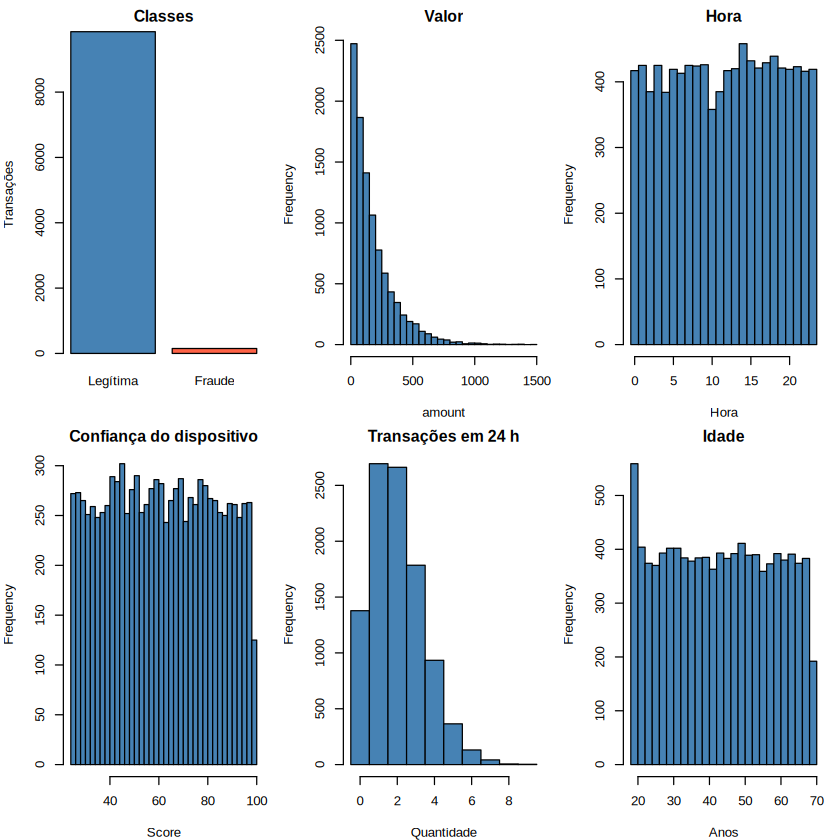

In [54]:
classe <- table(dados$is_fraud)
data.frame(classe = names(classe), n = as.integer(classe), proporcao = round(prop.table(classe), 4))
numericas <- c("amount", "transaction_hour", "device_trust_score",
               "velocity_last_24h", "cardholder_age")
resumo_num <- do.call(rbind, lapply(numericas, function(v) {
  x <- dados[[v]]
  data.frame(variavel = v, media = mean(x), mediana = median(x), dp = sd(x),
             q1 = unname(quantile(x, .25)), q3 = unname(quantile(x, .75)),
             minimo = min(x), maximo = max(x))
}))
print(resumo_num, row.names = FALSE)
par(mfrow = c(2, 3), mar = c(4, 4, 2, 1))
barplot(classe, main = "Classes", ylab = "Transações", col = c("steelblue", "tomato"))
hist(dados$amount, breaks = 40, main = "Valor", xlab = "amount", col = "steelblue")
hist(dados$transaction_hour, breaks = seq(-.5, 23.5, 1), main = "Hora", xlab = "Hora", col = "steelblue")
hist(dados$device_trust_score, breaks = 30, main = "Confiança do dispositivo", xlab = "Score", col = "steelblue")
hist(dados$velocity_last_24h, breaks = seq(min(dados$velocity_last_24h)-.5,
     max(dados$velocity_last_24h)+.5, 1), main = "Transações em 24 h", xlab = "Quantidade", col = "steelblue")
hist(dados$cardholder_age, breaks = 20, main = "Idade", xlab = "Anos", col = "steelblue")
par(mfrow = c(1, 1))


Há **151 fraudes (1,51%)** e 9.849 transações legítimas. Acurácia isolada seria enganosa: prever sempre “legítima” já daria 98,49%. `amount` é assimétrico à direita, motivo para apresentar também quantis e usar testes não paramétricos nas comparações planejadas.

### 2.3 Relações com a classe e entre variáveis

Calculamos taxas de fraude por categoria e por indicadores binários. Os boxplots têm valores extremos ocultos apenas para a **visualização**; nenhum registro é removido dos cálculos. Correlações numéricas resumem relações lineares e não demonstram causalidade.


 merchant_category 
       grupo legitimas fraudes taxa_fraude
    Clothing      2026      24  0.01170732
 Electronics      1899      24  0.01248050
        Food      2058      35  0.01672241
     Grocery      1905      39  0.02006173
      Travel      1961      29  0.01457286

 foreign_transaction 
 grupo legitimas fraudes taxa_fraude
   Não      8953      69 0.007647972
   Sim       896      82 0.083844581

 location_mismatch 
 grupo legitimas fraudes taxa_fraude
   Não      9064      79  0.00864049
   Sim       785      72  0.08401400
   grupo legitimas fraudes taxa_fraude
 06–23 h      7518      27 0.003578529
 00–05 h      2331     124 0.050509165
           variavel   classe    n      media mediana    q1      q3
             amount Legítima 9849 175.333015  122.11 50.99 241.650
             amount   Fraude  151 216.182980  118.94 41.53 341.695
   transaction_hour Legítima 9849  11.712154   12.00  6.00  18.000
   transaction_hour   Fraude  151   3.841060    2.00  1.00   3.000
 de

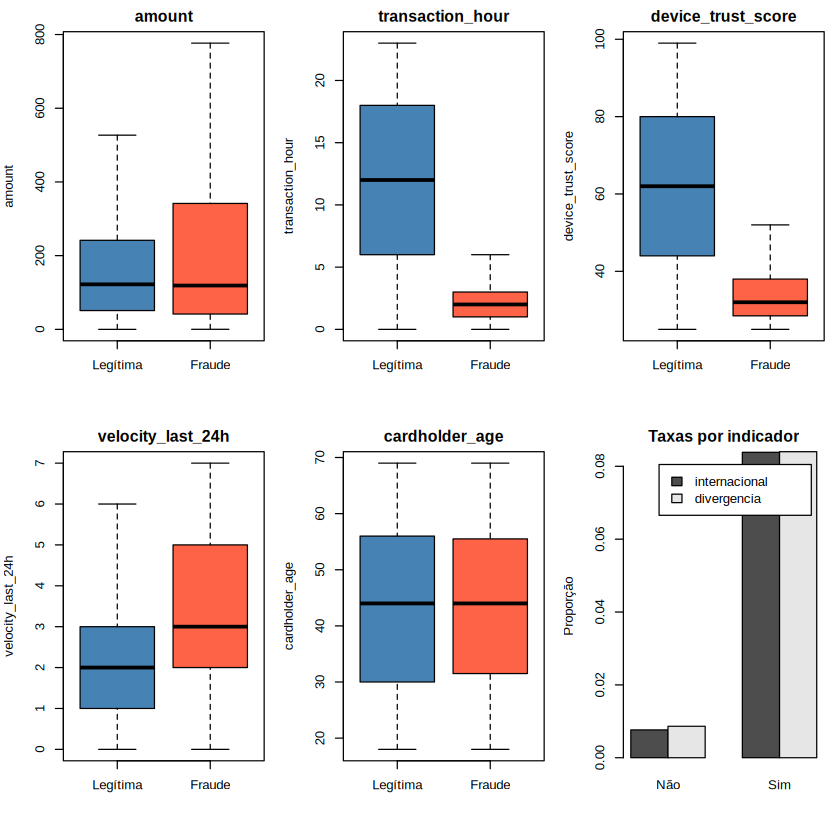

In [55]:
taxas <- function(variavel) {
  tab <- table(dados[[variavel]], dados$is_fraud)
  data.frame(grupo = rownames(tab), legitimas = tab[, "Legítima"],
             fraudes = tab[, "Fraude"], taxa_fraude = tab[, "Fraude"] / rowSums(tab),
             row.names = NULL)
}
for (v in c("merchant_category", "foreign_transaction", "location_mismatch")) {
  cat("\n", v, "\n")
  print(taxas(v), row.names = FALSE)
}
dados$madrugada <- factor(ifelse(dados$transaction_hour < 6, "00–05 h", "06–23 h"),
                          levels = c("06–23 h", "00–05 h"))
print(taxas("madrugada"), row.names = FALSE)
resumo_classe <- do.call(rbind, lapply(numericas, function(v) {
  do.call(rbind, lapply(levels(dados$is_fraud), function(g) {
    x <- dados[[v]][dados$is_fraud == g]
    data.frame(variavel = v, classe = g, n = length(x), media = mean(x),
               mediana = median(x), q1 = unname(quantile(x, .25)),
               q3 = unname(quantile(x, .75)))
  }))
}))
print(resumo_classe, row.names = FALSE)
par(mfrow = c(2, 3), mar = c(5, 4, 2, 1))
for (v in numericas) {
  boxplot(dados[[v]] ~ dados$is_fraud, main = v, xlab = "", ylab = v,
          outline = FALSE, col = c("steelblue", "tomato"))
}
taxas_indicadores <- rbind(internacional = taxas("foreign_transaction")$taxa_fraude,
                          divergencia = taxas("location_mismatch")$taxa_fraude)
colnames(taxas_indicadores) <- c("Não", "Sim")
barplot(taxas_indicadores, beside = TRUE, legend.text = TRUE,
        main = "Taxas por indicador", ylab = "Proporção")
par(mfrow = c(1, 1))


                    amount transaction_hour device_trust_score
amount               1.000           -0.003              0.004
transaction_hour    -0.003            1.000              0.004
device_trust_score   0.004            0.004              1.000
velocity_last_24h    0.004           -0.006             -0.001
cardholder_age       0.004            0.012              0.014
foreign_transaction -0.006            0.000              0.013
location_mismatch    0.013            0.005              0.002
is_fraud             0.006           -0.137             -0.138
                    velocity_last_24h cardholder_age foreign_transaction
amount                          0.004          0.004              -0.006
transaction_hour               -0.006          0.012               0.000
device_trust_score             -0.001          0.014               0.013
velocity_last_24h               1.000         -0.001              -0.007
cardholder_age                 -0.001          1.000               0

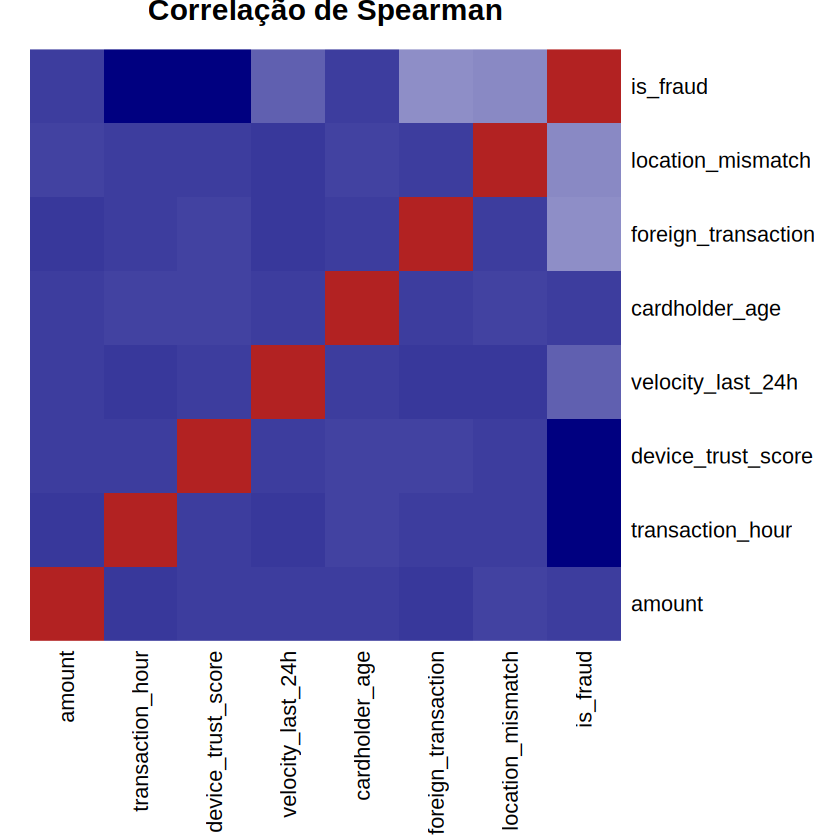

In [56]:
matriz <- dados[, numericas]
matriz$foreign_transaction <- as.integer(dados$foreign_transaction == "Sim")
matriz$location_mismatch <- as.integer(dados$location_mismatch == "Sim")
matriz$is_fraud <- as.integer(dados$is_fraud == "Fraude")
correlacoes <- cor(matriz, method = "spearman")
print(round(correlacoes, 3))
heatmap(correlacoes, Rowv = NA, Colv = NA, symm = TRUE,
        col = colorRampPalette(c("navy", "white", "firebrick"))(101),
        margins = c(10, 10), main = "Correlação de Spearman")


### 2.4 Insights e foco da validação

No conjunto analisado, a taxa de fraude é **8,38%** nas transações internacionais e **0,76%** nas nacionais; com divergência de localização é **8,40%**, contra **0,86%** sem divergência. A mediana do score de confiança é **32** nas fraudes e **62** nas legítimas; a mediana de transações nas últimas 24 horas é **3** contra **2**. Também há concentração de fraudes entre 00–05 h (5,05% contra 0,36%), mas essa faixa foi escolhida após observar os dados e é **exploratória**, sem teste confirmatório abaixo. Valor da transação tem média maior nas fraudes, mas mediana ligeiramente menor, logo não sustentamos uma conclusão simples com base só na média. Essas associações sugerem variáveis úteis para modelagem posterior, sem demonstrar que uma delas causa fraude. Como os dados são simulados, padrões podem refletir as regras usadas na geração.

## Validação Estatística

### 3.1 Hipóteses e plano de testes

Adotamos **α = 0,05** e quatro comparações, escolhidas pelos padrões da EDA. Para `foreign_transaction` e `location_mismatch`, a hipótese nula é independência entre o indicador e a classe; a alternativa é associação. Para `device_trust_score` e `velocity_last_24h`, a hipótese nula é igualdade das distribuições entre fraudes e legítimas; a alternativa é diferença. Os testes são **bicaudais**. Usamos Fisher exato nas tabelas 2×2, apropriado também quando há contagens pequenas, e Mann–Whitney/Wilcoxon para variáveis numéricas/discretas sem pressupor normalidade. Como existem empates, a aproximação assintótica é usada no teste de Wilcoxon. Ajustamos os quatro p-valores pelo método de Holm para controlar o erro familiar.

As transações são tratadas como observações independentes; o CSV não fornece identificador de cliente/cartão para conferir essa suposição. O teste de Wilcoxon compara distribuições, e só pode ser interpretado estritamente como teste de deslocamento de medianas sob formas de distribuição comparáveis.

In [57]:
legitimas <- dados$is_fraud == "Legítima"
fraudes <- dados$is_fraud == "Fraude"
teste_score <- wilcox.test(dados$device_trust_score[fraudes],
                           dados$device_trust_score[legitimas],
                           alternative = "two.sided", exact = FALSE)
teste_velocidade <- wilcox.test(dados$velocity_last_24h[fraudes],
                                dados$velocity_last_24h[legitimas],
                                alternative = "two.sided", exact = FALSE)
teste_internacional <- fisher.test(table(dados$foreign_transaction, dados$is_fraud))
teste_localizacao <- fisher.test(table(dados$location_mismatch, dados$is_fraud))
p_bruto <- c(dispositivo = teste_score$p.value,
             velocidade = teste_velocidade$p.value,
             internacional = teste_internacional$p.value,
             localizacao = teste_localizacao$p.value)
resultado <- data.frame(hipotese = names(p_bruto), p_bruto = unname(p_bruto),
                        p_holm = unname(p.adjust(p_bruto, method = "holm")),
                        row.names = NULL)
resultado$rejeita_H0_5pct <- resultado$p_holm < .05
print(resultado, row.names = FALSE, digits = 4)
cat("Odds ratio internacional (Fisher):", unname(teste_internacional$estimate),
    "| IC 95%:", teste_internacional$conf.int, "\n")
cat("Odds ratio divergência (Fisher):", unname(teste_localizacao$estimate),
    "| IC 95%:", teste_localizacao$conf.int, "\n")


      hipotese   p_bruto    p_holm rejeita_H0_5pct
   dispositivo 2.540e-43 7.620e-43            TRUE
    velocidade 8.882e-15 8.882e-15            TRUE
 internacional 1.123e-43 4.493e-43            TRUE
   localizacao 2.265e-37 4.531e-37            TRUE
Odds ratio internacional (Fisher): 11.86858 | IC 95%: 8.445581 16.72273 
Odds ratio divergência (Fisher): 10.51826 | IC 95%: 7.470028 14.78549 


### 3.2–3.3 Resultados e interpretação

Uma checagem independente do CSV encontrou p-valores extremamente pequenos nas quatro comparações, inclusive após Holm (todos **p ajustados < 10⁻¹⁴**). O código acima calcula os valores com R; pequenas diferenças numéricas entre programas podem ocorrer pela aproximação do Wilcoxon. Há evidência contra as quatro hipóteses nulas a 5%. O sentido das associações vem das taxas e medianas na EDA: fraudes aparecem mais entre transações internacionais e com divergência de localização, junto com score menor e velocidade maior. Os odds ratios amostrais para internacional e divergência são cerca de **11,9** e **10,5**, respectivamente; odds não são probabilidades e essas associações não implicam causalidade.

Como os mesmos dados serviram para **selecionar** as hipóteses após a EDA e para testá-las, os p-valores são uma verificação interna, não confirmação externa. A etapa seguinte do projeto deve avaliar os modelos em dados separados, com divisão estratificada e métricas adequadas à classe rara (recall, precisão e PR-AUC), evitando usar informação do teste no treinamento.

## Pré processamento dos dados

## Modelagem e aplicação do ensemble

## Resultados obtidos

## Conclusão